In [376]:
from pathlib import Path
import pandas as pd
import numpy as np
import pybedtools
from upsetplot import UpSet, from_memberships
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn2, venn3_circles
from collections import Counter

In [523]:
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
PREPROCESSING = Path("../preprocessing").resolve()
HIMORNA = DATA / "himorna"
BIOMART_INITIAL = DATA_INITIAL / "biomart"
GENCODE_INITIAL = DATA_INITIAL / "gencode"
ID_HISTORY_CONVERTER_RES = DATA / "id_history_converter_res"
HIMORNA_UPDATE = PREPROCESSING / "himorna_lncrna-gencode31_to_gencode47"

In [4]:
%%time
to_file =  HIMORNA / "himorna_peaks-hm_meth-assoc.tsv.gz"
himorna_peaks_assoc = pd.read_csv(to_file, sep="\t")

<timed exec>:2: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.


CPU times: user 19min, sys: 5min 14s, total: 24min 15s
Wall time: 24min 12s


In [5]:
himorna_peaks_assoc.shape

(696878891, 12)

In [6]:
himorna_peaks_assoc.head(3)

,hm,lnc,lnc_ens,peak,chrom,start,end,corr,gene_chrom,gene_start,gene_end,gene_ens
0,H3K27ac,AP005060.1,ENSG00000279885,peak_389211,chr18,10441312,10441530,0.500356,NaN,NaN,NaN,NaN
1,H3K27ac,AC012409.3,ENSG00000277135,peak_389211,chr18,10441312,10441530,0.480105,NaN,NaN,NaN,NaN
2,H3K27ac,AC116651.1,ENSG00000273133,peak_389211,chr18,10441312,10441530,0.450511,NaN,NaN,NaN,NaN


In [52]:
himorna_hm_lncrna = himorna_peaks_assoc[["hm", "lnc", "lnc_ens"]].drop_duplicates()
himorna_hm_lncrna.shape

(15021, 3)

In [53]:
himorna_hm_lncrna

,hm,lnc,lnc_ens
0,H3K27ac,AP005060.1,ENSG00000279885
1,H3K27ac,AC012409.3,ENSG00000277135
2,H3K27ac,AC116651.1,ENSG00000273133
3,H3K27ac,AGAP11,ENSG00000271880
4,H3K27ac,AC015961.2,ENSG00000267707
...,...,...,...
692782935,methylation,NaN,ENSG00000261126
696448344,methylation,NaN,ENSG00000261168
696874534,methylation,NaN,ENSG00000261189
696874858,methylation,NaN,ENSG00000261202


In [94]:
himorna_lncrna = himorna_hm_lncrna["lnc_ens"].unique()
len(himorna_lncrna)

4434

In [560]:
def gencode_gtf_processing(to_gtf_file):
    gtf_file_GENCODE = to_gtf_file
    anno_GENCODE = pd.read_csv(gtf_file_GENCODE, sep="\t", header=None, skiprows=5)
    anno_GENCODE["ens_gene"] = anno_GENCODE[8].apply(lambda x: x.split(" ")[1].replace('"', '').replace(';', '').split(".")[0])
    anno_GENCODE["gene_name"] = anno_GENCODE[8].apply(lambda x: x.split("gene_name")[1].split(" ")[1].replace('"', '').replace(';', ''))
    anno_GENCODE["unique_genome_reg_name"] = anno_GENCODE["ens_gene"] + "-" + anno_GENCODE[2]
    gencode_hg38 = anno_GENCODE[[0, 3, 4, "unique_genome_reg_name", 5, 6, "ens_gene", "gene_name"]]
    mask = gencode_hg38["unique_genome_reg_name"].apply(lambda x: "gene" in x)
    gencode_genes_hg38 = gencode_hg38[mask]
    gencode_genes_hg38.head(2)
    gencode_genes_hg38 = gencode_genes_hg38.rename(columns={0:"chrom", 3:"start", 4:"end", "unique_genome_reg_name":"name", 5:"score", 6:"strand"})
    gencode_genes_hg38 = gencode_genes_hg38.drop_duplicates()
    gencode_genes_hg38 = gencode_genes_hg38.drop_duplicates()
    gencode_genes_hg38["gene_ens--gene_name"] = gencode_genes_hg38["ens_gene"] + "--" + gencode_genes_hg38["gene_name"]
    return gencode_genes_hg38

In [211]:
to_file = GENCODE_INITIAL / "gencode.v31.basic.annotation.gtf.gz"
gencode_v31_genes_hg38 = gencode_gtf_processing(to_gtf_file=to_file)
gencode_v31_genes_hg38.shape

(60603, 9)

In [212]:
gencode_v31_genes_hg38.head(3)

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
0,chr1,11869,14409,ENSG00000223972-gene,.,+,ENSG00000223972,DDX11L1,ENSG00000223972--DDX11L1
12,chr1,14404,29570,ENSG00000227232-gene,.,-,ENSG00000227232,WASH7P,ENSG00000227232--WASH7P
25,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267--MIR6859-1


In [213]:
to_file = GENCODE_INITIAL / "gencode.v47.basic.annotation.gtf.gz"
gencode_v47_genes_hg38 = gencode_gtf_processing(to_gtf_file=to_file)
gencode_v47_genes_hg38.shape

(78724, 9)

In [214]:
gencode_v47_genes_hg38.head(3)

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
0,chr1,11121,24894,ENSG00000290825-gene,.,+,ENSG00000290825,DDX11L16,ENSG00000290825--DDX11L16
6,chr1,12010,13670,ENSG00000223972-gene,.,+,ENSG00000223972,DDX11L1,ENSG00000223972--DDX11L1
14,chr1,14356,30744,ENSG00000310526-gene,.,-,ENSG00000310526,WASH7P,ENSG00000310526--WASH7P


In [319]:
to_file = GENCODE_INITIAL / "gencode.v49.basic.annotation.gtf.gz"
gencode_v49_genes_hg38 = gencode_gtf_processing(to_gtf_file=to_file)
gencode_v49_genes_hg38.shape

(78691, 9)

In [317]:
gencode_v31_genes_hg38["gene_name"].apply(lambda x: "ENSG" not in x).sum()

60603

In [318]:
gencode_v47_genes_hg38["gene_name"].apply(lambda x: "ENSG" not in x).sum()

42727

In [320]:
gencode_v49_genes_hg38["gene_name"].apply(lambda x: "ENSG" not in x).sum()

43030

In [555]:
gencode_v47_genes_hg38[gencode_v47_genes_hg38["gene_name"] == "VENTXP1"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
2146487,chrX,26557675,26558330,ENSG00000259849-gene,.,+,ENSG00000259849,VENTXP1,ENSG00000259849--VENTXP1
2146490,chrX,26558247,26881029,ENSG00000293226-gene,.,+,ENSG00000293226,VENTXP1,ENSG00000293226--VENTXP1


In [554]:
gencode_v49_genes_hg38[gencode_v49_genes_hg38["gene_name"] == "VENTXP1"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
5691810,chrX,26557675,26558330,ENSG00000259849-gene,.,+,ENSG00000259849,VENTXP1,ENSG00000259849--VENTXP1
5691813,chrX,26558247,26881029,ENSG00000293226-gene,.,+,ENSG00000293226,VENTXP1,ENSG00000293226--VENTXP1


## Проверка

In [73]:
gencode_v31_genes_hg38[gencode_v31_genes_hg38["ens_gene"] == "ENSG00000278267"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens-gene_name
25,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267-MIR6859-1


In [346]:
gencode_v47_genes_hg38[gencode_v47_genes_hg38["ens_gene"] == "ENSG00000278267"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
120,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267--MIR6859-1


In [347]:
gencode_v47_genes_hg38["ens_gene"].isin(himorna_lncrna).sum()

4138

In [55]:
mask = (himorna_hm_lncrna["hm"] != "methylation")
himorna_hm_lncrna_1 = himorna_hm_lncrna[mask]
himorna_hm_lncrna_2 = himorna_hm_lncrna[~mask]

In [58]:
himorna_hm_lncrna_1["lnc_ens"].nunique()

4145

In [59]:
himorna_hm_lncrna_2["lnc_ens"].nunique()

1705

In [60]:
mask = himorna_hm_lncrna_1["lnc_ens"].isin(gencode_v31_genes_hg38["ens_gene"])
himorna_hm_lncrna_1[~mask]

,hm,lnc,lnc_ens


In [61]:
mask = himorna_hm_lncrna_2["lnc_ens"].isin(gencode_v31_genes_hg38["ens_gene"])
himorna_hm_lncrna_2[~mask]

,hm,lnc,lnc_ens


In [63]:
len(set(himorna_hm_lncrna_2["lnc_ens"].to_list()) - set(himorna_hm_lncrna_1["lnc_ens"].to_list()))

289

Мы убедились, что и оригинальные данные химорны, и данные метилирования были взяты из gencode.v31. \
Поэтому будем работать с переносом напрямую между gencode.v31 и gencode.v47.

## Обновление идентификаторов

Существует несколько подходов к решению этой проблемы. Универсального варианта нет, поэтому мы будем использовать комбинированный подход:
1) Если ensg между разметками не меняется - считаем, что пара найдена.
2) Если в новой версии разметки такого гена нет, то запускаем id_history_converter.

In [381]:
len(himorna_lncrna)

4434

In [353]:
mask = gencode_v47_genes_hg38["ens_gene"].isin(himorna_lncrna)
good_genes = gencode_v47_genes_hg38[mask]["ens_gene"]
len(good_genes)

4138

In [356]:
bad_genes = set(himorna_lncrna) - set(good_genes)
len(bad_genes)

296

4138 однозначных соответствий. Запустим id_history_converter для 296 проблемных генов.

In [358]:
with open(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-id-gencode_v31-himorna_lncrna.txt", "w") as file:
    file.writelines("%s\n" % line.split("-")[0] for line in bad_genes)

In [360]:
bad_genes_history = pd.read_csv(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-id-gencode_v31-himorna_lncrna-history.txt", skipinitialspace=True)
bad_genes_history = bad_genes_history.rename(columns=lambda x: x.strip())
bad_genes_history

,Old stable ID,New stable ID,Release,Mapping score
0,ENSG00000278266.1,ENSG00000278266.1,98,0.9
1,ENSG00000278266.1,ENSG00000278266.1,99,0.9
2,ENSG00000278266.1,ENSG00000278266.1,100,0.9
3,ENSG00000278266.1,ENSG00000286791.2,113,0.99
4,Old stable ID,New stable ID,Release,Mapping score
...,...,...,...,...
1926,Old stable ID,New stable ID,Release,Mapping score
1927,ENSG00000260409.1,ENSG00000260409.1,98,0.9
1928,ENSG00000260409.1,ENSG00000260409.1,99,0.9
1929,ENSG00000260409.1,ENSG00000260409.1,100,0.9


In [361]:
mask = bad_genes_history["Old stable ID"].apply(lambda x: "ENSG" in x)
bad_genes_history = bad_genes_history[mask].reset_index(drop=True)

In [362]:
bad_genes_history.head(2)

,Old stable ID,New stable ID,Release,Mapping score
0,ENSG00000278266.1,ENSG00000278266.1,98,0.9
1,ENSG00000278266.1,ENSG00000278266.1,99,0.9


In [365]:
bad_genes_history["Old stable ID without v"] = bad_genes_history["Old stable ID"].apply(lambda x: x.split(".")[0])
bad_genes_history["New stable ID without v"] = bad_genes_history["New stable ID"].apply(lambda x: x.split(".")[0])

In [366]:
bad_genes_history["Old stable ID without v"].nunique()

296

In [368]:
ensgr_bad_genes = set(bad_genes) - set(bad_genes_history["Old stable ID without v"].unique())
len(ensgr_bad_genes)

0

In [369]:
bad_genes_history["Release"] = bad_genes_history["Release"].astype(float)

In [370]:
def check_retired_conditions(df):
    # Находим все строки с <retired>
    df = df.reset_index(drop=True)
    retired_rows = df[df['New stable ID without v'] == '<retired>']
    if len(retired_rows) == 0:
        return False
    # Проверка 1: что <retired> только в одном экземпляре
    is_single_instance = len(retired_rows) == 1
    
    # Получаем индекс строки с <retired>
    retired_index = retired_rows.index[0]
    total_rows = len(df)
    
    # Проверка 2: что <retired> не на последней строке
    is_not_last = retired_index != total_rows - 1
    
    # Проверка 3: что <retired> не на предпоследней строке  
    is_not_second_last = retired_index != total_rows - 2
    if is_not_second_last == False:
        if df.iloc[retired_index, 2] == df.iloc[retired_index-1, 2]:
            is_not_second_last = True
    if is_single_instance & is_not_last & is_not_second_last:
        return True
    return False

In [371]:
#нужно модифицировать функцию для случаев, когда ген вырождается в несколько
def bad_history_analyzer(ensg_id, bad_genes_history):
    query_res = bad_genes_history.query(f"`Old stable ID without v` == '{ensg_id}'")
    query_res_length = len(query_res)
    if query_res_length == 0:
        new_ensg = "<retired>"
        return new_ensg
    if check_retired_conditions(df=query_res):
        new_ensg = "<retired>-to-many"
        return new_ensg
    else:
        new_ensg = query_res.iloc[-1, 5]
    return new_ensg

In [372]:
bad_genes_resolutions = {i.split("-")[0]:bad_history_analyzer(ensg_id=i.split("-")[0], bad_genes_history=bad_genes_history) for i in bad_genes}

In [373]:
len(bad_genes_resolutions)

296

In [374]:
df_bad_genes_resolutions = pd.DataFrame({"name":bad_genes_resolutions.keys(), "name_latest":bad_genes_resolutions.values()})
df_bad_genes_resolutions

,name,name_latest
0,ENSG00000278266,ENSG00000286791
1,ENSG00000273771,ENSG00000247809
2,ENSG00000273038,<retired>
3,ENSG00000259820,ENSG00000289405
4,ENSG00000267787,ENSG00000267040
...,...,...
291,ENSG00000261409,<retired>
292,ENSG00000227540,ENSG00000236756
293,ENSG00000243179,ENSG00000234199
294,ENSG00000261222,ENSG00000182352


In [377]:
Counter(df_bad_genes_resolutions["name_latest"])["<retired>"]

91

In [378]:
Counter(df_bad_genes_resolutions["name_latest"])["<retired>-to-many"]

0

In [401]:
mask = df_bad_genes_resolutions["name_latest"].apply(lambda x: "ENSG" in x)
df_bad_genes_resolutions[mask]

,name,name_latest
0,ENSG00000278266,ENSG00000286791
1,ENSG00000273771,ENSG00000247809
3,ENSG00000259820,ENSG00000289405
4,ENSG00000267787,ENSG00000267040
5,ENSG00000161149,ENSG00000284130
...,...,...
289,ENSG00000260163,ENSG00000286971
292,ENSG00000227540,ENSG00000236756
293,ENSG00000243179,ENSG00000234199
294,ENSG00000261222,ENSG00000182352


In [411]:
set(df_bad_genes_resolutions[mask]["name_latest"]) - set(gencode_v47_genes_hg38["ens_gene"])# гены, которые по каким-то причинам не перешли в gencode 47

{'ENSG00000233937', 'ENSG00000237352', 'ENSG00000248671', 'ENSG00000272446'}

In [422]:
205 + 4138 - 4

4339

И того, при помощи id_history_converter удалось восстановить id 4339 генов. По его версии 91 ens_gene устарел. Проверим их с помощью методики, описанной в статье Гриши: \
Пересечем гены gencode 31 и gencode 47 с помощью pybedtools:

In [425]:
"ENSG00000267034" in gencode_v47_genes_hg38["ens_gene"].to_list()

False

In [426]:
"ENSG00000267034" in himorna_lncrna

True

In [429]:
df_bad_genes_resolutions[df_bad_genes_resolutions["name"] == "ENSG00000280076"]

,name,name_latest
187,ENSG00000280076,<retired>


## Пересечение разметок

In [430]:
gencode_v31_genes_hg38

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
0,chr1,11869,14409,ENSG00000223972-gene,.,+,ENSG00000223972,DDX11L1,ENSG00000223972--DDX11L1
12,chr1,14404,29570,ENSG00000227232-gene,.,-,ENSG00000227232,WASH7P,ENSG00000227232--WASH7P
25,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267--MIR6859-1
28,chr1,29554,31109,ENSG00000243485-gene,.,+,ENSG00000243485,MIR1302-2HG,ENSG00000243485--MIR1302-2HG
36,chr1,30366,30503,ENSG00000284332-gene,.,+,ENSG00000284332,MIR1302-2,ENSG00000284332--MIR1302-2
...,...,...,...,...,...,...,...,...,...
1756483,chrM,14149,14673,ENSG00000198695-gene,.,-,ENSG00000198695,MT-ND6,ENSG00000198695--MT-ND6
1756488,chrM,14674,14742,ENSG00000210194-gene,.,-,ENSG00000210194,MT-TE,ENSG00000210194--MT-TE
1756491,chrM,14747,15887,ENSG00000198727-gene,.,+,ENSG00000198727,MT-CYB,ENSG00000198727--MT-CYB
1756496,chrM,15888,15953,ENSG00000210195-gene,.,+,ENSG00000210195,MT-TT,ENSG00000210195--MT-TT


In [431]:
gencode_v31_genes_hg38[["chrom","start","end","gene_ens--gene_name","score","strand"]]

,chrom,start,end,gene_ens--gene_name,score,strand
0,chr1,11869,14409,ENSG00000223972--DDX11L1,.,+
12,chr1,14404,29570,ENSG00000227232--WASH7P,.,-
25,chr1,17369,17436,ENSG00000278267--MIR6859-1,.,-
28,chr1,29554,31109,ENSG00000243485--MIR1302-2HG,.,+
36,chr1,30366,30503,ENSG00000284332--MIR1302-2,.,+
...,...,...,...,...,...,...
1756483,chrM,14149,14673,ENSG00000198695--MT-ND6,.,-
1756488,chrM,14674,14742,ENSG00000210194--MT-TE,.,-
1756491,chrM,14747,15887,ENSG00000198727--MT-CYB,.,+
1756496,chrM,15888,15953,ENSG00000210195--MT-TT,.,+


In [432]:
gencode_v31_hg38_sortbed = pybedtools.BedTool.from_dataframe(gencode_v31_genes_hg38[["chrom","start","end","gene_ens--gene_name","score","strand"]]).sort()
gencode_v31_hg38_sortbed.head(3)

chr1	11869	14409	ENSG00000223972--DDX11L1	.	+
 chr1	14404	29570	ENSG00000227232--WASH7P	.	-
 chr1	17369	17436	ENSG00000278267--MIR6859-1	.	-
 

In [433]:
gencode_v47_hg38_sortbed = pybedtools.BedTool.from_dataframe(gencode_v47_genes_hg38[["chrom","start","end","gene_ens--gene_name","score","strand"]]).sort()
gencode_v47_hg38_sortbed.head(3)

chr1	11121	24894	ENSG00000290825--DDX11L16	.	+
 chr1	12010	13670	ENSG00000223972--DDX11L1	.	+
 chr1	14356	30744	ENSG00000310526--WASH7P	.	-
 

In [434]:
gencode_v31_overlap_gencode_v47 = gencode_v31_hg38_sortbed.intersect(gencode_v47_hg38_sortbed, wao=True, s=True)#-loj

In [435]:
gencode_v31_overlap_gencode_v47 = gencode_v31_overlap_gencode_v47.to_dataframe(disable_auto_names=True, header=None)
gencode_v31_overlap_gencode_v47

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,chr1,11869,14409,ENSG00000223972--DDX11L1,.,+,chr1,12010,13670,ENSG00000223972--DDX11L1,.,+,1660
1,chr1,11869,14409,ENSG00000223972--DDX11L1,.,+,chr1,11121,24894,ENSG00000290825--DDX11L16,.,+,2540
2,chr1,14404,29570,ENSG00000227232--WASH7P,.,-,chr1,17369,17436,ENSG00000278267--MIR6859-1,.,-,67
3,chr1,14404,29570,ENSG00000227232--WASH7P,.,-,chr1,14356,30744,ENSG00000310526--WASH7P,.,-,15166
4,chr1,14404,29570,ENSG00000227232--WASH7P,.,-,chr1,14696,24886,ENSG00000227232--WASH7P,.,-,10190
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91878,chrY,57201143,57203357,ENSG00000185203--WASIR1,.,-,chrY,57201135,57203405,ENSG00000292370--WASIR1,.,-,2214
91879,chrY,57207346,57212230,ENSG00000182484--WASH6P,.,+,chrY,57207346,57212230,ENSG00000292372--WASH6P,.,+,4884
91880,chrY,57207346,57212230,ENSG00000182484--WASH6P,.,+,chrY,57190738,57208756,ENSG00000292369--ENSG00000292369,.,+,1410
91881,chrY,57212184,57214397,ENSG00000227159--DDX11L16,.,-,chrY,57208516,57215634,ENSG00000310542--ENSG00000310542,.,-,2213


In [436]:
mask = gencode_v31_overlap_gencode_v47[3].apply(lambda x: x.split("--")[0] in himorna_lncrna)
gencode_v31_overlap_gencode_v47_himorna_subset = gencode_v31_overlap_gencode_v47[mask]
gencode_v31_overlap_gencode_v47_himorna_subset.shape

(7327, 13)

In [437]:
gencode_v31_overlap_gencode_v47_himorna_subset = gencode_v31_overlap_gencode_v47_himorna_subset.rename(columns={0:"f-chrom", 1:"f-strart", 2:"f-end", 3:"f-name", 4:"f-score", 5:"f-strand",
                                            6:"g-chrom", 7:"g-strart", 8:"g-end", 9:"g-name", 10:"g-score", 11:"g-strand",
                                            12:"overlap"})
gencode_v31_overlap_gencode_v47_himorna_subset

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap
18,chr1,89295,133723,ENSG00000238009--AL627309.1,.,-,chr1,89551,91105,ENSG00000239945--ENSG00000239945,.,-,1554
19,chr1,89295,133723,ENSG00000238009--AL627309.1,.,-,chr1,89295,181719,ENSG00000241860--ENSG00000241860,.,-,44428
20,chr1,89551,91105,ENSG00000239945--AL627309.3,.,-,chr1,89551,91105,ENSG00000239945--ENSG00000239945,.,-,1554
21,chr1,89551,91105,ENSG00000239945--AL627309.3,.,-,chr1,89295,181719,ENSG00000241860--ENSG00000241860,.,-,1554
28,chr1,139790,140339,ENSG00000239906--AL627309.2,.,-,chr1,139790,140339,ENSG00000239906--ENSG00000239906,.,-,549
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91543,chrY,18772706,19077563,ENSG00000176728--TTTY14,.,-,chrY,18731440,18773735,ENSG00000169953--HSFY2,.,-,1029
91544,chrY,18772706,19077563,ENSG00000176728--TTTY14,.,-,chrY,18772706,19077555,ENSG00000176728--TTTY14,.,-,304849
91577,chrY,19691941,19694606,ENSG00000260197--AC010889.1,.,-,chrY,19691941,19694606,ENSG00000260197--ENSG00000260197,.,-,2665
91584,chrY,20464916,20575519,ENSG00000229236--TTTY10,.,-,chrY,20570222,20570519,ENSG00000277438--KDM5DP1,.,-,297


In [438]:
%%time
gencode_v31_overlap_gencode_v47_himorna_subset["merge_len"] = gencode_v31_overlap_gencode_v47_himorna_subset[["f-strart", "f-end", "g-strart", "g-end"]].max(axis=1) - gencode_v31_overlap_gencode_v47_himorna_subset[["f-strart", "f-end", "g-strart", "g-end"]].min(axis=1)

CPU times: user 4.82 ms, sys: 204 μs, total: 5.02 ms
Wall time: 4.37 ms


In [439]:
gencode_v31_overlap_gencode_v47_himorna_subset["jaccard"] = gencode_v31_overlap_gencode_v47_himorna_subset["overlap"] / gencode_v31_overlap_gencode_v47_himorna_subset["merge_len"]

In [440]:
gencode_v31_overlap_gencode_v47_himorna_subset["jaccard > 0.8"] = gencode_v31_overlap_gencode_v47_himorna_subset["jaccard"] > 0.8

In [441]:
gencode_v31_overlap_gencode_v47_himorna_subset["g-name"] = gencode_v31_overlap_gencode_v47_himorna_subset["g-name"].replace(".", "--")

In [442]:
gencode_v31_overlap_gencode_v47_himorna_subset["gene_en-metric"] = \
            gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: x.split("--")[0]) == gencode_v31_overlap_gencode_v47_himorna_subset["g-name"].apply(lambda x: x.split("--")[0])

In [443]:
gencode_v31_overlap_gencode_v47_himorna_subset["gene_name-metric"] = \
            gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: x.split("--")[1]) == gencode_v31_overlap_gencode_v47_himorna_subset["g-name"].apply(lambda x: x.split("--")[1])

In [458]:
gencode_v31_overlap_gencode_v47_himorna_subset["f-ens_name"] = gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: x.split("--")[0])

In [457]:
mask = df_bad_genes_resolutions["name_latest"].apply(lambda x: "ENSG" not in x)
df_bad_genes_resolutions_retired = df_bad_genes_resolutions[mask]
df_bad_genes_resolutions_retired

,name,name_latest
2,ENSG00000273038,<retired>
15,ENSG00000272308,<retired>
17,ENSG00000275560,<retired>
19,ENSG00000204282,<retired>
21,ENSG00000271895,<retired>
...,...,...
282,ENSG00000272904,<retired>
286,ENSG00000206532,<retired>
287,ENSG00000271259,<retired>
290,ENSG00000270040,<retired>


In [ ]:
df_bad_genes_resolutions_retired

In [456]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: x.split("--")[0] == "ENSG00000204282")
gencode_v31_overlap_gencode_v47_himorna_subset[mask]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.8,gene_en-metric,gene_name-metric
39117,chr17,78107398,78111799,ENSG00000204282--TNRC6C-AS1,.,-,chr17,78107397,78132407,ENSG00000141524--TMC6,.,-,4401,25010,0.17597,False,False,False


In [462]:
gencode_v31_overlap_gencode_v47_himorna_subset_retired = pd.merge(left=df_bad_genes_resolutions_retired, right=gencode_v31_overlap_gencode_v47_himorna_subset, how="left", left_on="name", right_on="f-ens_name")

In [466]:
gencode_v31_overlap_gencode_v47_himorna_subset_retired[gencode_v31_overlap_gencode_v47_himorna_subset_retired["gene_name-metric"] == True]

,name,name_latest,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,...,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.8,gene_en-metric,gene_name-metric,f-ens_name
9,ENSG00000269900,<retired>,chr9,35657751,35658018,ENSG00000269900--RMRP,.,-,chr9,35657754,...,ENSG00000277027--RMRP,.,-,263,267,0.985019,True,False,True,ENSG00000269900


Так, в ходе пересечения увидели, что один из 91 генов (ENSG00000269900) однозначно отобралился в ENSG00000277027. Индекс Жаккара составил 0.98, gena_name совпал.

Создадим таблицу - сличение lncRNA из Himorna:

In [470]:
himorna_lncrna

array(['ENSG00000279885', 'ENSG00000277135', 'ENSG00000273133', ...,
       'ENSG00000260672', 'ENSG00000261093', 'ENSG00000261222'],
      dtype=object)

In [ ]:
new_ensg = []
for ensg in himorna_lncrna:
    if ensg in good_genes.to_list():
        new_ensg.append(ensg)
    else:
        if ensg in 

In [473]:
df_good_genes = pd.DataFrame({"name":good_genes, "name_latest":good_genes})
df_good_genes.head(3)

,name,name_latest
261,ENSG00000239945,ENSG00000239945
285,ENSG00000239906,ENSG00000239906
627,ENSG00000225880,ENSG00000225880


In [475]:
himorna_gencode31_to_gencode47 = pd.concat([df_good_genes, df_bad_genes_resolutions])

Удаляем 'ENSG00000233937', 'ENSG00000237352', 'ENSG00000248671', 'ENSG00000272446' и заменяем значение для "ENSG00000269900"--> "ENSG00000277027"

In [486]:
for i in ['ENSG00000233937', 'ENSG00000237352', 'ENSG00000248671', 'ENSG00000272446']:
    indx = himorna_gencode31_to_gencode47[himorna_gencode31_to_gencode47["name"] == i].index[0]
    himorna_gencode31_to_gencode47.loc[indx, "name_latest"] = "<retired>"

In [487]:
indx = himorna_gencode31_to_gencode47[himorna_gencode31_to_gencode47["name"] == "ENSG00000269900"].index[0]
himorna_gencode31_to_gencode47.loc[indx, "name_latest"] = "ENSG00000277027"

In [508]:
len(himorna_gencode31_to_gencode47)

4434

In [490]:
#Проверка, не забыли ли мы какие-то гены
assert len(himorna_gencode31_to_gencode47) == len(himorna_hm_lncrna["lnc_ens"].unique())

In [498]:
himorna_gencode31_to_gencode47_ambigus_genes = pd.DataFrame(himorna_gencode31_to_gencode47["name_latest"].value_counts())
himorna_gencode31_to_gencode47_ambigus_genes

,count
name_latest,
<retired>,94
ENSG00000103472,3
ENSG00000239569,3
ENSG00000197182,3
ENSG00000259804,3
...,...
ENSG00000279078,1
ENSG00000273270,1
ENSG00000242588,1


In [503]:
himorna_gencode31_to_gencode47_ambigus_genes[himorna_gencode31_to_gencode47_ambigus_genes["count"] >= 2]

,count
name_latest,
<retired>,94
ENSG00000103472,3
ENSG00000239569,3
ENSG00000197182,3
ENSG00000259804,3
...,...
ENSG00000258537,2
ENSG00000230337,2
ENSG00000233098,2


К своему удивлению обнаружили, что некоторые гены вырождаются в один. Как с этим быть? Перепресуждаем пики?

In [495]:
himorna_gencode31_to_gencode47[himorna_gencode31_to_gencode47["name_latest"] == "ENSG00000103472"]

,name,name_latest
1676814,ENSG00000103472,ENSG00000103472
43,ENSG00000260517,ENSG00000103472
76,ENSG00000198106,ENSG00000103472


In [547]:
gencode_v31_genes_hg38[gencode_v31_genes_hg38["ens_gene"] == "ENSG00000103472"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
1311992,chr16,29074976,29116718,ENSG00000103472-gene,.,+,ENSG00000103472,RRN3P2,ENSG00000103472--RRN3P2


In [548]:
gencode_v31_genes_hg38[gencode_v31_genes_hg38["ens_gene"] == "ENSG00000260517"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
1312045,chr16,29139661,29216706,ENSG00000260517-gene,.,+,ENSG00000260517,AC009093.2,ENSG00000260517--AC009093.2


In [549]:
gencode_v31_genes_hg38[gencode_v31_genes_hg38["ens_gene"] == "ENSG00000198106"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
1312077,chr16,29291220,29372110,ENSG00000198106-gene,.,+,ENSG00000198106,AC025279.1,ENSG00000198106--AC025279.1


In [550]:
gencode_v47_genes_hg38[gencode_v47_genes_hg38["ens_gene"] == "ENSG00000103472"]

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
1676814,chr16,29074796,29403423,ENSG00000103472-gene,.,+,ENSG00000103472,RRN3P2,ENSG00000103472--RRN3P2


In [509]:
mask = himorna_gencode31_to_gencode47["name_latest"].apply(lambda x: x != "<retired>")
himorna_gencode31_to_gencode47[mask]["name_latest"].nunique()

4244

In [510]:
himorna_gencode31_to_gencode47["name"].nunique()

4434

In [511]:
himorna_gencode31_to_gencode47[himorna_gencode31_to_gencode47["name_latest"] == "<retired>"]

,name,name_latest
2,ENSG00000273038,<retired>
15,ENSG00000272308,<retired>
17,ENSG00000275560,<retired>
19,ENSG00000204282,<retired>
21,ENSG00000271895,<retired>
...,...,...
284,ENSG00000237352,<retired>
286,ENSG00000206532,<retired>
287,ENSG00000271259,<retired>
290,ENSG00000270040,<retired>


In [513]:
mask = (himorna_gencode31_to_gencode47["name_latest"] != "<retired>")
mask1 = (himorna_gencode31_to_gencode47[mask]["name"] == himorna_gencode31_to_gencode47[mask]["name_latest"])
himorna_gencode31_to_gencode47[mask][mask1]

,name,name_latest
261,ENSG00000239945,ENSG00000239945
285,ENSG00000239906,ENSG00000239906
627,ENSG00000225880,ENSG00000225880
843,ENSG00000237491,ENSG00000237491
892,ENSG00000177757,ENSG00000177757
...,...,...
2217758,ENSG00000231535,ENSG00000231535
2218387,ENSG00000273906,ENSG00000273906
2221796,ENSG00000176728,ENSG00000176728
2222237,ENSG00000260197,ENSG00000260197


In [517]:
mask = (himorna_gencode31_to_gencode47["name_latest"] != "<retired>")
mask1 = (himorna_gencode31_to_gencode47[mask]["name"] == himorna_gencode31_to_gencode47[mask]["name_latest"])
himorna_gencode31_to_gencode47[mask][~mask1]

,name,name_latest
0,ENSG00000278266,ENSG00000286791
1,ENSG00000273771,ENSG00000247809
3,ENSG00000259820,ENSG00000289405
4,ENSG00000267787,ENSG00000267040
5,ENSG00000161149,ENSG00000284130
...,...,...
289,ENSG00000260163,ENSG00000286971
292,ENSG00000227540,ENSG00000236756
293,ENSG00000243179,ENSG00000234199
294,ENSG00000261222,ENSG00000182352


Итого: Было 4434 lncRNA. Стало 4244. \
4138 ens_id не изменились. \
202 ens_id обновились на актуальный ens_id. 91 из них отобрализись в меньшее количество актуальных ens_id \
94 ens_id устарели.

Добавим gene_name из gencode.47

In [520]:
himorna_gencode31_to_gencode47 = pd.merge(left=himorna_gencode31_to_gencode47, right=gencode_v47_genes_hg38[["ens_gene", "gene_name"]], how="left", left_on="name_latest", right_on="ens_gene")[["name","name_latest","gene_name"]]
himorna_gencode31_to_gencode47

,name,name_latest,gene_name
0,ENSG00000239945,ENSG00000239945,ENSG00000239945
1,ENSG00000239906,ENSG00000239906,ENSG00000239906
2,ENSG00000225880,ENSG00000225880,LINC00115
3,ENSG00000237491,ENSG00000237491,LINC01409
4,ENSG00000177757,ENSG00000177757,FAM87B
...,...,...,...
4429,ENSG00000261409,<retired>,NaN
4430,ENSG00000227540,ENSG00000236756,DNAJC9-AS1
4431,ENSG00000243179,ENSG00000234199,LINC01191
4432,ENSG00000261222,ENSG00000182352,CD300LD-AS1


In [521]:
himorna_gencode31_to_gencode47 = himorna_gencode31_to_gencode47.rename(columns={"name":"ens_gene-gencode31", "name_latest":"ens_gene-gencode47", "gene_name":"gene_name-gencode47"})

In [522]:
himorna_gencode31_to_gencode47

,ens_gene-gencode31,ens_gene-gencode47,gene_name-gencode47
0,ENSG00000239945,ENSG00000239945,ENSG00000239945
1,ENSG00000239906,ENSG00000239906,ENSG00000239906
2,ENSG00000225880,ENSG00000225880,LINC00115
3,ENSG00000237491,ENSG00000237491,LINC01409
4,ENSG00000177757,ENSG00000177757,FAM87B
...,...,...,...
4429,ENSG00000261409,<retired>,NaN
4430,ENSG00000227540,ENSG00000236756,DNAJC9-AS1
4431,ENSG00000243179,ENSG00000234199,LINC01191
4432,ENSG00000261222,ENSG00000182352,CD300LD-AS1


In [525]:
to_save = "himorna_lncrna-gencode31_to_gencode47.tsv"
himorna_gencode31_to_gencode47.to_csv(HIMORNA_UPDATE / to_save, sep="\t", index=False)

In [530]:
himorna_gencode31_to_gencode47["gene_name-gencode47"] = himorna_gencode31_to_gencode47["gene_name-gencode47"].astype(str)
mask = himorna_gencode31_to_gencode47["gene_name-gencode47"].apply(lambda x: "ENSG" in x)
himorna_gencode31_to_gencode47[mask]

,ens_gene-gencode31,ens_gene-gencode47,gene_name-gencode47
0,ENSG00000239945,ENSG00000239945,ENSG00000239945
1,ENSG00000239906,ENSG00000239906,ENSG00000239906
8,ENSG00000272512,ENSG00000272512,ENSG00000272512
9,ENSG00000272141,ENSG00000272141,ENSG00000272141
10,ENSG00000260179,ENSG00000260179,ENSG00000260179
...,...,...,...
4416,ENSG00000240996,ENSG00000235100,ENSG00000235100
4421,ENSG00000258088,ENSG00000258077,ENSG00000258077
4426,ENSG00000261305,ENSG00000301866,ENSG00000301866
4427,ENSG00000260163,ENSG00000286971,ENSG00000286971


По какой-то причине в последних версиях gencode отходит от gene_name. Практически для половины генов lncRNA из himorna в качестве gene_name продублирован ens_id.

Теперь обновим главную таблицу:

In [531]:
himorna_peaks_assoc

,hm,lnc,lnc_ens,peak,chrom,start,end,corr,gene_chrom,gene_start,gene_end,gene_ens
0,H3K27ac,AP005060.1,ENSG00000279885,peak_389211,chr18,10441312,10441530,0.500356,NaN,NaN,NaN,NaN
1,H3K27ac,AC012409.3,ENSG00000277135,peak_389211,chr18,10441312,10441530,0.480105,NaN,NaN,NaN,NaN
2,H3K27ac,AC116651.1,ENSG00000273133,peak_389211,chr18,10441312,10441530,0.450511,NaN,NaN,NaN,NaN
3,H3K27ac,AGAP11,ENSG00000271880,peak_389211,chr18,10441312,10441530,0.491645,NaN,NaN,NaN,NaN
4,H3K27ac,AC015961.2,ENSG00000267707,peak_389211,chr18,10441312,10441530,0.473911,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
696878886,methylation,NaN,ENSG00000261222,peak_47069123,chr8,9741473,9741474,-0.890000,chr8,9551766.0,9788424.0,ENSG00000173273-gene
696878887,methylation,NaN,ENSG00000261222,peak_47069123,chr8,9741473,9741474,-0.890000,chr8,9740848.0,9741768.0,ENSG00000207701-gene
696878888,methylation,NaN,ENSG00000261222,peak_47097647,chr8,10827627,10827628,-0.879000,chr8,10712751.0,10839868.0,ENSG00000171056-gene
696878889,methylation,NaN,ENSG00000261222,peak_47097647,chr8,10827627,10827628,-0.879000,chr8,10725399.0,10839868.0,ENSG00000258724-gene


In [532]:
himorna_gencode31_to_gencode47_no_retired = himorna_gencode31_to_gencode47.query("`ens_gene-gencode47` != '<retired>'")
himorna_gencode31_to_gencode47_no_retired

,ens_gene-gencode31,ens_gene-gencode47,gene_name-gencode47
0,ENSG00000239945,ENSG00000239945,ENSG00000239945
1,ENSG00000239906,ENSG00000239906,ENSG00000239906
2,ENSG00000225880,ENSG00000225880,LINC00115
3,ENSG00000237491,ENSG00000237491,LINC01409
4,ENSG00000177757,ENSG00000177757,FAM87B
...,...,...,...
4427,ENSG00000260163,ENSG00000286971,ENSG00000286971
4430,ENSG00000227540,ENSG00000236756,DNAJC9-AS1
4431,ENSG00000243179,ENSG00000234199,LINC01191
4432,ENSG00000261222,ENSG00000182352,CD300LD-AS1


In [534]:
%%time
himorna_peaks_assoc_gencode47 = pd.merge(left=himorna_peaks_assoc, right=himorna_gencode31_to_gencode47, how="left", left_on="lnc_ens", right_on="ens_gene-gencode31")
himorna_peaks_assoc_gencode47.shape

CPU times: user 3min 20s, sys: 2min 21s, total: 5min 41s
Wall time: 5min 39s


(696878891, 15)

In [535]:
himorna_peaks_assoc_gencode47.head(3)

,hm,lnc,lnc_ens,peak,chrom,start,end,corr,gene_chrom,gene_start,gene_end,gene_ens,ens_gene-gencode31,ens_gene-gencode47,gene_name-gencode47
0,H3K27ac,AP005060.1,ENSG00000279885,peak_389211,chr18,10441312,10441530,0.500356,NaN,NaN,NaN,NaN,ENSG00000279885,ENSG00000279885,ENSG00000279885
1,H3K27ac,AC012409.3,ENSG00000277135,peak_389211,chr18,10441312,10441530,0.480105,NaN,NaN,NaN,NaN,ENSG00000277135,ENSG00000277135,ENSG00000277135
2,H3K27ac,AC116651.1,ENSG00000273133,peak_389211,chr18,10441312,10441530,0.450511,NaN,NaN,NaN,NaN,ENSG00000273133,ENSG00000273133,ENSG00000273133


In [551]:
himorna_peaks_assoc_gencode47 = himorna_peaks_assoc_gencode47[['hm', 'lnc', 'lnc_ens', 'ens_gene-gencode31', 'ens_gene-gencode47', 'gene_name-gencode47', 'peak', 'chrom', 'start', 'end', 'corr',
       'gene_chrom', 'gene_start', 'gene_end', 'gene_ens']]

In [552]:
to_save =  HIMORNA / "himorna_peaks-hm_meth-gencode47-assoc-l2permissive_hg38.tsv.gz"
himorna_peaks_assoc_gencode47.to_csv(to_save, sep="\t", compression="gzip", index=False)

In [538]:
himorna_peaks_assoc_gencode47["hm"].unique()

array(['H3K27ac', 'H3K27me3', 'H3K36me3', 'H3K4me1', 'H3K4me2', 'H3K4me3',
       'H3K79me2', 'H3K9ac', 'H3K9me3', 'H4K20me1', 'methylation'],
      dtype=object)

In [539]:
himorna_peaks_assoc_gencode47["lnc_ens"].nunique()

4434

In [540]:
himorna_peaks_assoc_gencode47["ens_gene-gencode31"].nunique()

4434

In [541]:
himorna_peaks_assoc_gencode47["ens_gene-gencode47"].nunique()

4245

In [446]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: x.split("--")[0] in bad_genes)
gencode_v31_overlap_gencode_v47_himorna_subset[mask].query("`jaccard > 0.8` == True")

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.8,gene_en-metric,gene_name-metric
2529,chr1,55329288,56070513,ENSG00000234810--AL603840.1,.,+,chr1,55329288,56070515,ENSG00000233079--LINC01755,.,+,741225,741227,0.999997,True,False,False
4695,chr1,152168125,152445456,ENSG00000237975--FLG-AS1,.,+,chr1,152165553,152445456,ENSG00000236427--CCDST,.,+,277331,279903,0.990811,True,False,False
10081,chr10,86970741,87010126,ENSG00000271880--AGAP11,.,+,chr10,86968432,87007922,ENSG00000148671--ADIRF,.,+,37181,41694,0.891759,True,False,False
14396,chr11,71673885,71818238,ENSG00000248671--AP003498.1,.,-,chr11,71673885,71813859,ENSG00000293546--ALG1L9P,.,-,139974,144353,0.969665,True,False,False
14397,chr11,71673885,71818238,ENSG00000248671--AP003498.1,.,-,chr11,71674083,71813414,ENSG00000293694--ENSG00000293694,.,-,139331,144353,0.965210,True,False,False
18526,chr12,54058254,54122235,ENSG00000248265--AC023794.1,.,+,chr12,54058140,54122235,ENSG00000249388--FLJ12825,.,+,63981,64095,0.998221,True,False,False
24513,chr14,53169010,53883740,ENSG00000237356--AL365295.1,.,+,chr14,53152282,53883750,ENSG00000258731--DDHD1-DT,.,+,714730,731468,0.977117,True,False,False
40845,chr18,57639455,57738603,ENSG00000267787--AC027097.2,.,+,chr18,57629870,57738678,ENSG00000267040--ATP8B1-AS1,.,+,99148,108808,0.911220,True,False,False
43001,chr19,19761038,19821716,ENSG00000267581--AC011477.4,.,-,chr19,19761038,19821751,ENSG00000081665--ZNF506,.,-,60678,60713,0.999424,True,False,False
47242,chr2,55282350,55346049,ENSG00000240401--AC012358.3,.,+,chr2,55279535,55346049,ENSG00000293422--PRORSD1P,.,+,63699,66514,0.957678,True,False,False


In [348]:
gencode_v31_overlap_gencode_v47_himorna_subset[gencode_v31_overlap_gencode_v47_himorna_subset["gene_en-metric"] == True]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
2,20,chr1,89551,91105,ENSG00000239945--AL627309.3,.,-,chr1,89551,91105,ENSG00000239945--ENSG00000239945,.,-,1554,1554,1.000000,True,True,False
4,28,chr1,139790,140339,ENSG00000239906--AL627309.2,.,-,chr1,139790,140339,ENSG00000239906--ENSG00000239906,.,-,549,549,1.000000,True,True,False
7,99,chr1,778747,810065,ENSG00000237491--AL669831.5,.,+,chr1,778739,810066,ENSG00000237491--LINC01409,.,+,31318,31327,0.999713,True,True,False
8,104,chr1,817371,819837,ENSG00000177757--FAM87B,.,+,chr1,817363,819842,ENSG00000177757--FAM87B,.,+,2466,2479,0.994756,True,True,True
9,105,chr1,825138,868202,ENSG00000228794--LINC01128,.,+,chr1,825138,868835,ENSG00000228794--LINC01128,.,+,43064,43697,0.985514,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7312,91167,chrY,3002887,3200509,ENSG00000231535--LINC00278,.,+,chrY,3002887,3200509,ENSG00000231535--LINC00278,.,+,197622,197622,1.000000,True,True,True
7313,91220,chrY,6918682,6920791,ENSG00000273906--AC011297.1,.,+,chrY,6918682,6920791,ENSG00000273906--ENSG00000273906,.,+,2109,2109,1.000000,True,True,False
7323,91544,chrY,18772706,19077563,ENSG00000176728--TTTY14,.,-,chrY,18772706,19077555,ENSG00000176728--TTTY14,.,-,304849,304857,0.999974,True,True,True
7324,91577,chrY,19691941,19694606,ENSG00000260197--AC010889.1,.,-,chrY,19691941,19694606,ENSG00000260197--ENSG00000260197,.,-,2665,2665,1.000000,True,True,False


In [345]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset["f-name"].apply(lambda x: "ENSG00000279885" in x)
gencode_v31_overlap_gencode_v47_himorna_subset[mask]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
3536,39635,chr18,6394847,6398020,ENSG00000279885--AP005060.1,.,-,chr18,6394847,6398020,ENSG00000279885--ENSG00000279885,.,-,3173,3173,1.00000,True,True,False
3537,39636,chr18,6394847,6398020,ENSG00000279885--AP005060.1,.,-,chr18,5954706,6415237,ENSG00000154655--L3MBTL4,.,-,3173,460531,0.00689,False,False,False


In [326]:
gencode_v31_overlap_gencode_v47_himorna_subset[gencode_v31_overlap_gencode_v47_himorna_subset["f-name"] == "ENSG00000238009--AL627309.1"]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
0,18,chr1,89295,133723,ENSG00000238009--AL627309.1,.,-,chr1,89551,91105,ENSG00000239945--ENSG00000239945,.,-,1554,44428,0.034978,False,False,False
1,19,chr1,89295,133723,ENSG00000238009--AL627309.1,.,-,chr1,89295,181719,ENSG00000241860--ENSG00000241860,.,-,44428,92424,0.480698,False,False,False


In [294]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset["jaccard > 0.99"]
gencode_v31_overlap_gencode_v47_himorna_subset[mask]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
2,20,chr1,89551,91105,ENSG00000239945--AL627309.3,.,-,chr1,89551,91105,ENSG00000239945--ENSG00000239945,.,-,1554,1554,1.000000,True,True,False
4,28,chr1,139790,140339,ENSG00000239906--AL627309.2,.,-,chr1,139790,140339,ENSG00000239906--ENSG00000239906,.,-,549,549,1.000000,True,True,False
7,99,chr1,778747,810065,ENSG00000237491--AL669831.5,.,+,chr1,778739,810066,ENSG00000237491--LINC01409,.,+,31318,31327,0.999713,True,True,False
8,104,chr1,817371,819837,ENSG00000177757--FAM87B,.,+,chr1,817363,819842,ENSG00000177757--FAM87B,.,+,2466,2479,0.994756,True,True,True
15,121,chr1,995966,998051,ENSG00000272512--AL645608.7,.,-,chr1,995966,998051,ENSG00000272512--ENSG00000272512,.,-,2085,2085,1.000000,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7312,91167,chrY,3002887,3200509,ENSG00000231535--LINC00278,.,+,chrY,3002887,3200509,ENSG00000231535--LINC00278,.,+,197622,197622,1.000000,True,True,True
7313,91220,chrY,6918682,6920791,ENSG00000273906--AC011297.1,.,+,chrY,6918682,6920791,ENSG00000273906--ENSG00000273906,.,+,2109,2109,1.000000,True,True,False
7323,91544,chrY,18772706,19077563,ENSG00000176728--TTTY14,.,-,chrY,18772706,19077555,ENSG00000176728--TTTY14,.,-,304849,304857,0.999974,True,True,True
7324,91577,chrY,19691941,19694606,ENSG00000260197--AC010889.1,.,-,chrY,19691941,19694606,ENSG00000260197--ENSG00000260197,.,-,2665,2665,1.000000,True,True,False


In [299]:
gencode_v31_overlap_gencode_v47_himorna_subset[mask].groupby(by="f-name").aggregate(
    Число_элементов_в_группе=("g-name", "nunique")
).sort_values(by="Число_элементов_в_группе", ascending=False)

,Число_элементов_в_группе
f-name,
ENSG00000223571--DHRSX-IT1,2
ENSG00000093100--AC016026.1,1
ENSG00000272509--AC087752.4,1
ENSG00000272447--AL135925.1,1
ENSG00000272455--AL391244.2,1
...,...
ENSG00000254614--AP003068.2,1
ENSG00000254648--AP000911.2,1
ENSG00000254665--AC091053.1,1


In [314]:
mask = (gencode_v31_overlap_gencode_v47_himorna_subset["jaccard > 0.99"] == False) & (gencode_v31_overlap_gencode_v47_himorna_subset["gene_en-metric"])
gencode_v31_overlap_gencode_v47_himorna_subset[mask]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
9,105,chr1,825138,868202,ENSG00000228794--LINC01128,.,+,chr1,825138,868835,ENSG00000228794--LINC01128,.,+,43064,43697,0.985514,False,True,True
10,106,chr1,826206,827522,ENSG00000225880--LINC00115,.,-,chr1,586945,827989,ENSG00000225880--LINC00115,.,-,1316,241044,0.005460,False,True,True
12,108,chr1,868071,876903,ENSG00000230368--FAM41C,.,-,chr1,868052,877032,ENSG00000230368--FAM41C,.,-,8832,8980,0.983519,False,True,True
14,115,chr1,916865,921016,ENSG00000223764--LINC02593,.,-,chr1,916865,925614,ENSG00000223764--LINC02593,.,-,4151,8749,0.474454,False,True,True
18,151,chr1,1275223,1280420,ENSG00000230415--LINC01786,.,+,chr1,1274033,1280420,ENSG00000230415--LINC01786,.,+,5197,6387,0.813684,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7288,90570,chrX,136639539,136642429,ENSG00000233093--LINC00892,.,+,chrX,136639531,136642546,ENSG00000233093--LINC00892,.,+,2890,3015,0.958541,False,True,True
7292,90761,chrX,147909431,147911817,ENSG00000268066--FMR1-AS1,.,-,chrX,147891981,147911817,ENSG00000268066--FMR1-AS1,.,-,2386,19836,0.120286,False,True,True
7302,90990,chrX,154396878,154398816,ENSG00000280195--AC245140.2,.,-,chrX,154396878,154398842,ENSG00000280195--ENSG00000280195,.,-,1938,1964,0.986762,False,True,False
7303,90995,chrX,154424380,154428479,ENSG00000197180--AC244090.1,.,-,chrX,154424377,154428549,ENSG00000197180--ATP6AP1-DT,.,-,4099,4172,0.982502,False,True,False


In [316]:
mask = (gencode_v31_overlap_gencode_v47_himorna_subset["f-name"] == "ENSG00000224216--AC234781.1")
gencode_v31_overlap_gencode_v47_himorna_subset[mask]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
7306,91077,chrX,155334858,155351957,ENSG00000224216--AC234781.1,.,-,chrX,155334858,155382951,ENSG00000224216--ENSG00000224216,.,-,17099,48093,0.35554,False,True,False


In [300]:
gencode_v31_overlap_gencode_v47_himorna_subset[gencode_v31_overlap_gencode_v47_himorna_subset["f-name"] == "ENSG00000223571--DHRSX-IT1"]

,index,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,jaccard > 0.99,gene_en-metric,gene_name-metric
7158,87741,chrX,2334295,2336410,ENSG00000223571--DHRSX-IT1,.,-,chrX,2334295,2336410,ENSG00000223571--DHRSX-IT1,.,-,2115,2115,1.000000,True,True,True
7159,87742,chrX,2334295,2336410,ENSG00000223571--DHRSX-IT1,.,-,chrX,2219506,2502805,ENSG00000169084--DHRSX,.,-,2115,283299,0.007466,False,False,False
7310,91138,chrY,2334295,2336410,ENSG00000223571--DHRSX-IT1,.,-,chrY,2334295,2336410,ENSG00000292337--DHRSX-IT1,.,-,2115,2115,1.000000,True,False,True
7311,91139,chrY,2334295,2336410,ENSG00000223571--DHRSX-IT1,.,-,chrY,2219506,2502805,ENSG00000292338--DHRSX,.,-,2115,283299,0.007466,False,False,False


In [264]:
gencode_v31_overlap_gencode_v47_himorna_subset = gencode_v31_overlap_gencode_v47_himorna_subset.reset_index()
upset_df = gencode_v31_overlap_gencode_v47_himorna_subset.groupby(by=["jaccard > 0.99","gene_en-metric","gene_name-metric"]).aggregate(
        Число_пар=("index", "count")
).reset_index()
upset_df

,jaccard > 0.99,gene_en-metric,gene_name-metric,Число_пар
0,False,False,False,3168
1,False,False,True,12
2,False,True,False,805
3,False,True,True,632
4,True,False,False,7
5,True,False,True,2
6,True,True,False,2065
7,True,True,True,636


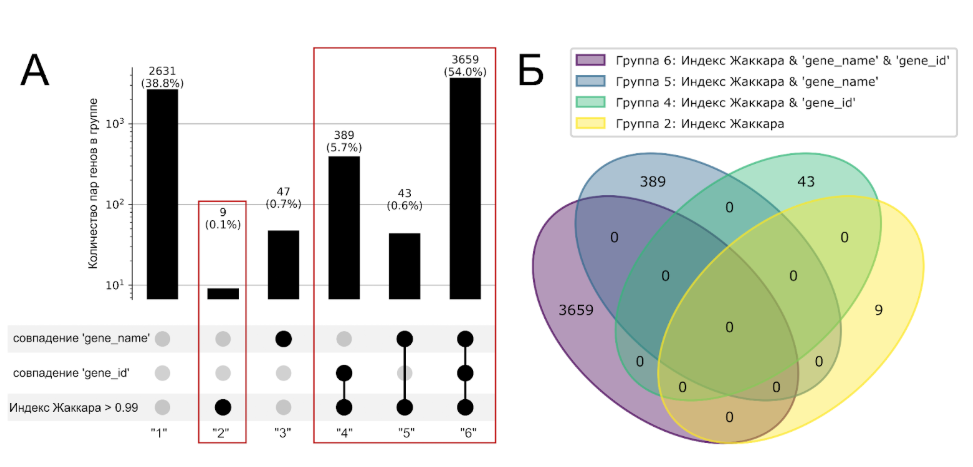

/export/home/agletdinov/miniforge3/envs/work/lib/python3.12/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/export/home/agletdinov/miniforge3/envs/work/lib/python3.12/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original obj

<Figure size 1200x1500 with 0 Axes>

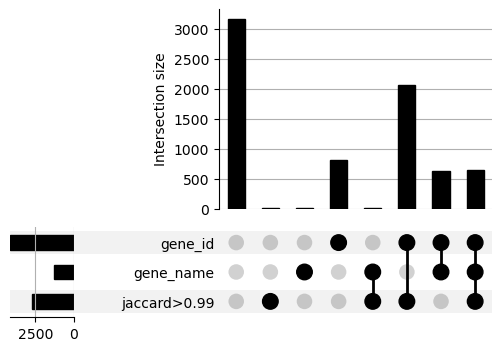

In [312]:
memberships = []
sizes = []

for _, row in upset_df.iterrows():
    mem = []
    if row["gene_name-metric"]: mem.append("gene_name")
    if row["gene_en-metric"]:  mem.append("gene_id")
    if row["jaccard > 0.99"]:  mem.append("jaccard>0.99")
    memberships.append(mem)
    sizes.append(row["Число_пар"])

upset_data = from_memberships(memberships, data=sizes)

plt.figure(figsize=(12,15))
UpSet(upset_data, sort_by='degree', sort_categories_by="-input", show_percentages=False).plot()
plt.tight_layout()
plt.show()

In [290]:
# Создаем словарь с размерами множеств
sets = {
    "Группа 2 (Jaccard)": upset_df[(upset_df["jaccard > 0.99"]) & (~upset_df["gene_en-metric"]) & (~upset_df["gene_name-metric"])]["Число_пар"].sum(),
    "Группа 4 (Jaccard + gene_id)": upset_df[(upset_df["jaccard > 0.99"]) & (upset_df["gene_en-metric"]) & (~upset_df["gene_name-metric"])]["Число_пар"].sum(),
    "Группа 5 (Jaccard + gene_name)": upset_df[(upset_df["jaccard > 0.99"]) & (~upset_df["gene_en-metric"]) & (upset_df["gene_name-metric"])]["Число_пар"].sum(),
    "Группа 6 (Jaccard + gene_id + gene_name)": upset_df[(upset_df["jaccard > 0.99"]) & (upset_df["gene_en-metric"]) & (upset_df["gene_name-metric"])]["Число_пар"].sum(),
}

In [291]:
sets

{'Группа 2 (Jaccard)': 7,
 'Группа 4 (Jaccard + gene_id)': 2065,
 'Группа 5 (Jaccard + gene_name)': 2,
 'Группа 6 (Jaccard + gene_id + gene_name)': 636}

In [278]:
upset_df

,jaccard > 0.99,gene_en-metric,gene_name-metric,Число_пар
0,False,False,False,3168
1,False,False,True,12
2,False,True,False,805
3,False,True,True,632
4,True,False,False,7
5,True,False,True,2
6,True,True,False,2065
7,True,True,True,636


In [313]:
7+2+2065+636

2710

### Добавим инфорамцию о jaccard метрике

In [161]:
gencode_v31_overlap_gencode_v47_himorna_subset.groupby(by="f-name").aggregate(
          number_of_comapped_genes=("g-name", "nunique")   
    ).sort_values(by="number_of_comapped_genes", ascending=True).query("number_of_comapped_genes > 1")

,number_of_comapped_genes
f-name,
ENSG00000278475,2
ENSG00000277135,2
ENSG00000281530,2
ENSG00000278876,2
ENSG00000277589,2
...,...
ENSG00000255794,12
ENSG00000242759,12
ENSG00000258399,25


In [156]:
gencode_v31_overlap_gencode_v47_himorna_subset[gencode_v31_overlap_gencode_v47_himorna_subset["overlap"] == 0]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
80946,chr8,9555144,9556520,ENSG00000272267,.,-,.,-1,-1,.,-1,.,0,9556521,0.0
81043,chr8,11761256,11763223,ENSG00000255394,.,+,.,-1,-1,.,-1,.,0,11763224,0.0


In [165]:
mask = (gencode_v31_overlap_gencode_v47_himorna_subset["jaccard"] >= 0.99)
gencode_v31_overlap_gencode_v47_himorna_subset_signif = gencode_v31_overlap_gencode_v47_himorna_subset[mask]
gencode_v31_overlap_gencode_v47_himorna_subset_signif

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
20,chr1,89551,91105,ENSG00000239945,.,-,chr1,89551,91105,ENSG00000239945,.,-,1554,1554,1.000000
28,chr1,139790,140339,ENSG00000239906,.,-,chr1,139790,140339,ENSG00000239906,.,-,549,549,1.000000
99,chr1,778747,810065,ENSG00000237491,.,+,chr1,778739,810066,ENSG00000237491,.,+,31318,31327,0.999713
104,chr1,817371,819837,ENSG00000177757,.,+,chr1,817363,819842,ENSG00000177757,.,+,2466,2479,0.994756
121,chr1,995966,998051,ENSG00000272512,.,-,chr1,995966,998051,ENSG00000272512,.,-,2085,2085,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91167,chrY,3002887,3200509,ENSG00000231535,.,+,chrY,3002887,3200509,ENSG00000231535,.,+,197622,197622,1.000000
91220,chrY,6918682,6920791,ENSG00000273906,.,+,chrY,6918682,6920791,ENSG00000273906,.,+,2109,2109,1.000000
91544,chrY,18772706,19077563,ENSG00000176728,.,-,chrY,18772706,19077555,ENSG00000176728,.,-,304849,304857,0.999974
91577,chrY,19691941,19694606,ENSG00000260197,.,-,chrY,19691941,19694606,ENSG00000260197,.,-,2665,2665,1.000000


In [166]:
gencode_v31_overlap_gencode_v47_himorna_subset_signif["f-name"].nunique()

2709

In [167]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset_signif["f-name"].duplicated()
gencode_v31_overlap_gencode_v47_himorna_subset_signif[mask]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
91138,chrY,2334295,2336410,ENSG00000223571,.,-,chrY,2334295,2336410,ENSG00000292337,.,-,2115,2115,1.0


In [168]:
mask = gencode_v31_overlap_gencode_v47_himorna_subset_signif["f-name"] == "ENSG00000223571"
gencode_v31_overlap_gencode_v47_himorna_subset_signif[mask]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
87741,chrX,2334295,2336410,ENSG00000223571,.,-,chrX,2334295,2336410,ENSG00000223571,.,-,2115,2115,1.0
91138,chrY,2334295,2336410,ENSG00000223571,.,-,chrY,2334295,2336410,ENSG00000292337,.,-,2115,2115,1.0


In [185]:
lncrna_jaccard_ok = gencode_v31_overlap_gencode_v47_himorna_subset_signif["f-name"].unique()
len(lncrna_jaccard_ok)

2709

In [186]:
mask = gencode_v31_genes_hg38["name"].apply(lambda x: x.split("-")[0] in himorna_lncrna)
gencode_v31_genes_hg38_himorna_subset = gencode_v31_genes_hg38[mask]
gencode_v31_genes_hg38_himorna_subset.shape

(4438, 8)

In [187]:
gencode_v31_genes_hg38_himorna_subset

,chrom,start,end,name,score,strand,ens_gene,gene_name
73,chr1,89295,133723,ENSG00000238009-gene,.,-,ENSG00000238009,AL627309.1
84,chr1,89551,91105,ENSG00000239945-gene,.,-,ENSG00000239945,AL627309.3
97,chr1,139790,140339,ENSG00000239906-gene,.,-,ENSG00000239906,AL627309.2
292,chr1,778747,810065,ENSG00000237491-gene,.,+,ENSG00000237491,AL669831.5
336,chr1,817371,819837,ENSG00000177757-gene,.,+,ENSG00000177757,FAM87B
...,...,...,...,...,...,...,...,...
1749680,chrY,3002887,3200509,ENSG00000231535-gene,.,+,ENSG00000231535,LINC00278
1750230,chrY,6918682,6920791,ENSG00000273906-gene,.,+,ENSG00000273906,AC011297.1
1752922,chrY,18772706,19077563,ENSG00000176728-gene,.,-,ENSG00000176728,TTTY14
1753157,chrY,19691941,19694606,ENSG00000260197-gene,.,-,ENSG00000260197,AC010889.1


In [194]:
gencode_v31_genes_hg38_himorna_subset["jaccard"] = gencode_v31_genes_hg38_himorna_subset["ens_gene"].isin(lncrna_jaccard_ok)

/tmp/ipykernel_50337/4078787590.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gencode_v31_genes_hg38_himorna_subset["jaccard"] = gencode_v31_genes_hg38_himorna_subset["ens_gene"].isin(lncrna_jaccard_ok)


In [196]:
gencode_v31_genes_hg38_himorna_subset = gencode_v31_genes_hg38_himorna_subset[["chrom", "ens_gene", "gene_name", "jaccard"]]

### Добавим инфорамцию о соответствии ens_id и gene_name

In [197]:
gencode_v31_genes_hg38_himorna_subset

,chrom,ens_gene,gene_name,jaccard
73,chr1,ENSG00000238009,AL627309.1,False
84,chr1,ENSG00000239945,AL627309.3,True
97,chr1,ENSG00000239906,AL627309.2,True
292,chr1,ENSG00000237491,AL669831.5,True
336,chr1,ENSG00000177757,FAM87B,True
...,...,...,...,...
1749680,chrY,ENSG00000231535,LINC00278,True
1750230,chrY,ENSG00000273906,AC011297.1,True
1752922,chrY,ENSG00000176728,TTTY14,True
1753157,chrY,ENSG00000260197,AC010889.1,True


In [199]:
gencode_v31_genes_hg38_himorna_subset["ens_metric"] = gencode_v31_genes_hg38_himorna_subset["ens_gene"].isin(gencode_v47_genes_hg38["ens_gene"])

/tmp/ipykernel_50337/1531026465.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gencode_v31_genes_hg38_himorna_subset["ens_metric"] = gencode_v31_genes_hg38_himorna_subset["ens_gene"].isin(gencode_v47_genes_hg38["ens_gene"])


In [201]:
gencode_v31_genes_hg38_himorna_subset["name_metric"] = gencode_v31_genes_hg38_himorna_subset["gene_name"].isin(gencode_v47_genes_hg38["gene_name"])

/tmp/ipykernel_50337/2370076210.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gencode_v31_genes_hg38_himorna_subset["name_metric"] = gencode_v31_genes_hg38_himorna_subset["gene_name"].isin(gencode_v47_genes_hg38["gene_name"])


In [202]:
gencode_v31_genes_hg38_himorna_subset

,chrom,ens_gene,gene_name,jaccard,ens_metric,name_metric
73,chr1,ENSG00000238009,AL627309.1,False,False,False
84,chr1,ENSG00000239945,AL627309.3,True,True,False
97,chr1,ENSG00000239906,AL627309.2,True,True,False
292,chr1,ENSG00000237491,AL669831.5,True,True,False
336,chr1,ENSG00000177757,FAM87B,True,True,True
...,...,...,...,...,...,...
1749680,chrY,ENSG00000231535,LINC00278,True,True,True
1750230,chrY,ENSG00000273906,AC011297.1,True,True,False
1752922,chrY,ENSG00000176728,TTTY14,True,True,True
1753157,chrY,ENSG00000260197,AC010889.1,True,True,False


In [204]:
gencode_v31_genes_hg38_himorna_subset.query("(jaccard == False) & ((ens_metric == True) | (name_metric == True))")

,chrom,ens_gene,gene_name,jaccard,ens_metric,name_metric
340,chr1,ENSG00000228794,LINC01128,False,True,True
402,chr1,ENSG00000225880,LINC00115,False,True,True
405,chr1,ENSG00000230368,FAM41C,False,True,True
437,chr1,ENSG00000223764,LINC02593,False,True,True
1705,chr1,ENSG00000230415,LINC01786,False,True,True
...,...,...,...,...,...,...
1746593,chrX,ENSG00000197180,AC244090.1,False,True,False
1748158,chrX,ENSG00000224216,AC234781.1,False,True,False
1748560,chrY,ENSG00000281849,AL732314.6,False,True,False
1749054,chrY,ENSG00000236871,LINC00106,False,True,True


In [198]:
gencode_v47_genes_hg38

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
0,chr1,11121,24894,ENSG00000290825-gene,.,+,ENSG00000290825,DDX11L16,ENSG00000290825--DDX11L16
6,chr1,12010,13670,ENSG00000223972-gene,.,+,ENSG00000223972,DDX11L1,ENSG00000223972--DDX11L1
14,chr1,14356,30744,ENSG00000310526-gene,.,-,ENSG00000310526,WASH7P,ENSG00000310526--WASH7P
108,chr1,14696,24886,ENSG00000227232-gene,.,-,ENSG00000227232,WASH7P,ENSG00000227232--WASH7P
120,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267--MIR6859-1
...,...,...,...,...,...,...,...,...,...
2225559,chrM,14149,14673,ENSG00000198695-gene,.,-,ENSG00000198695,MT-ND6,ENSG00000198695--MT-ND6
2225564,chrM,14674,14742,ENSG00000210194-gene,.,-,ENSG00000210194,MT-TE,ENSG00000210194--MT-TE
2225567,chrM,14747,15887,ENSG00000198727-gene,.,+,ENSG00000198727,MT-CYB,ENSG00000198727--MT-CYB
2225572,chrM,15888,15953,ENSG00000210195-gene,.,+,ENSG00000210195,MT-TT,ENSG00000210195--MT-TT


In [ ]:
pd.merge(left=gencode_v31_genes_hg38_himorna_subset, right=gencode_v47_genes_hg38, how="left", left_on="ens_gene", right_on="ens_gene")